# Experiment 10 — Image Classification using a CNN

**Aim:** Classify CIFAR-10 colour images with a small convolutional neural network.

**Theory:** Convolution and pooling layers learn local image patterns and reduce spatial dimensions. A dense softmax layer maps the learned representation to one of ten classes.

**Dataset:** CIFAR-10 has 50,000 training and 10,000 test images (32×32 RGB) across ten classes. The supplied ZIP contains only `data_batch_1`, not all five training batches and the test batch, so this notebook uses the complete Keras dataset.

Supplied CIFAR archive is incomplete; using the complete Keras CIFAR-10 dataset.


Dataset source: tensorflow.keras.datasets.cifar10
Training images: (50000, 32, 32, 3) | labels: (50000,)
Test images:     (10000, 32, 32, 3) | labels: (10000,)


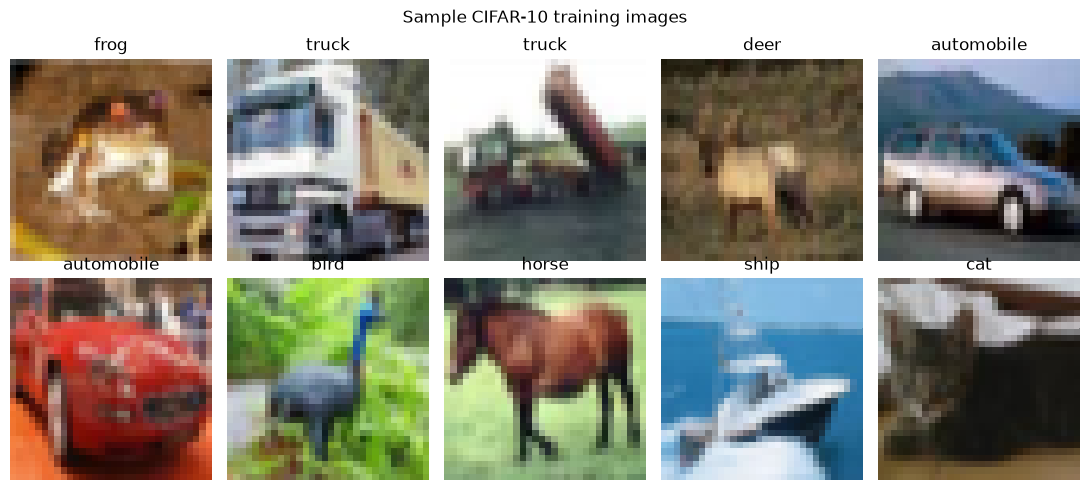

In [1]:
from pathlib import Path
from zipfile import ZipFile
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.datasets import cifar10

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
ROOT = Path.cwd()
if not (ROOT / 'datasets').is_dir():
    ROOT = ROOT.parent
FIGURES = ROOT / 'outputs' / 'figures'
RESULTS = ROOT / 'outputs' / 'results'
FIGURES.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

archive_members = []
for archive_path in sorted(list(ROOT.glob('*.zip')) + list((ROOT / 'datasets').glob('*.zip'))):
    with ZipFile(archive_path) as archive:
        archive_members.extend(Path(name).name for name in archive.namelist())
available_batches = {name for name in archive_members if name.startswith('data_batch_')}
if available_batches != {f'data_batch_{index}' for index in range(1, 6)} or 'test_batch' not in archive_members:
    print('Supplied CIFAR archive is incomplete; using the complete Keras CIFAR-10 dataset.')
else:
    print('A complete CIFAR-10 archive was found; Keras loader remains the standard dataset interface.')

(x_train, y_train), (x_test, y_test) = cifar10.load_data()
y_train = y_train.reshape(-1)
y_test = y_test.reshape(-1)
print('Dataset source: tensorflow.keras.datasets.cifar10')
print('Training images:', x_train.shape, '| labels:', y_train.shape)
print('Test images:    ', x_test.shape, '| labels:', y_test.shape)
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for ax, image, label in zip(axes.flat, x_train[:10], y_train[:10]):
    ax.imshow(image)
    ax.set_title(class_names[label])
    ax.axis('off')
fig.suptitle('Sample CIFAR-10 training images')
fig.tight_layout()
fig.savefig(FIGURES / 'exp10_cifar10_samples.png', dpi=150, bbox_inches='tight')
plt.show()

## Normalise and train the CNN

Images are scaled to [0, 1] in batched TensorFlow input pipelines to limit memory use. A fixed 10% validation split is drawn from the training set; the test set remains separate.

In [2]:
device_list = tf.config.list_physical_devices('GPU')
print('Available GPU devices:', device_list if device_list else 'none (training will use CPU)')

def normalise_image(image, label):
    return tf.cast(image, tf.float32) / 255.0, label

permutation = np.random.default_rng(SEED).permutation(len(x_train))
validation_indices = permutation[:5000]
training_indices = permutation[5000:]
autotune = tf.data.AUTOTUNE
train_dataset = tf.data.Dataset.from_tensor_slices((x_train[training_indices], y_train[training_indices]))
train_dataset = train_dataset.map(normalise_image, num_parallel_calls=autotune).shuffle(10000, seed=SEED).batch(128).prefetch(autotune)
validation_dataset = tf.data.Dataset.from_tensor_slices((x_train[validation_indices], y_train[validation_indices]))
validation_dataset = validation_dataset.map(normalise_image, num_parallel_calls=autotune).batch(128).prefetch(autotune)
test_dataset = tf.data.Dataset.from_tensor_slices((x_test, y_test))
test_dataset = test_dataset.map(normalise_image, num_parallel_calls=autotune).batch(128).prefetch(autotune)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),
    tf.keras.layers.Conv2D(32, 3, activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax'),
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_dataset, epochs=10, validation_data=validation_dataset, verbose=2)

Available GPU devices: none (training will use CPU)


Epoch 1/10


C:\Users\Kratik\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


352/352 - 28s - 79ms/step - accuracy: 0.4529 - loss: 1.5320 - val_accuracy: 0.5434 - val_loss: 1.2705


Epoch 2/10


...

352/352 - 22s - 62ms/step - accuracy: 0.7589 - loss: 0.6970 - val_accuracy: 0.7040 - val_loss: 0.8584


Epoch 9/10


352/352 - 19s - 55ms/step - accuracy: 0.7760 - loss: 0.6539 - val_accuracy: 0.6930 - val_loss: 0.8958


Epoch 10/10


352/352 - 23s - 66ms/step - accuracy: 0.7874 - loss: 0.6124 - val_accuracy: 0.7040 - val_loss: 0.8585


## Training curves and test predictions

Test metrics are measured only after training. The displayed examples include both their actual class and the model's predicted class.

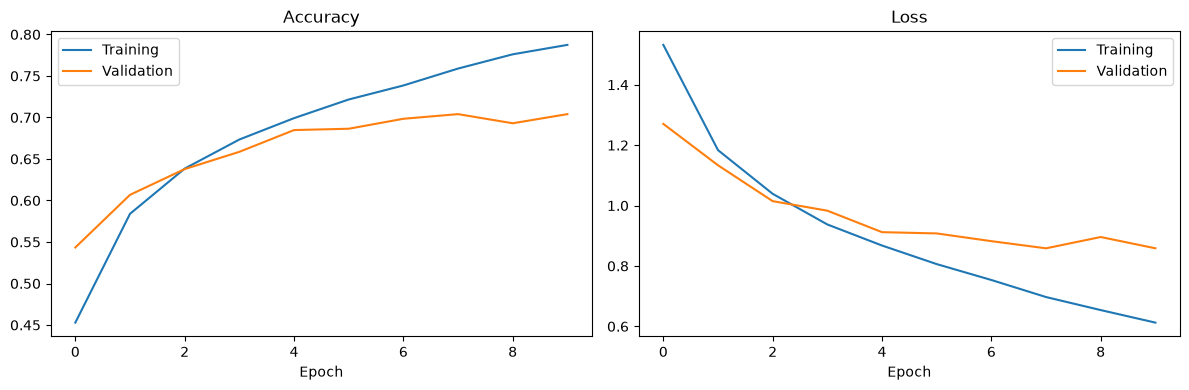

Test loss: 0.8756 | Test accuracy: 70.7100%


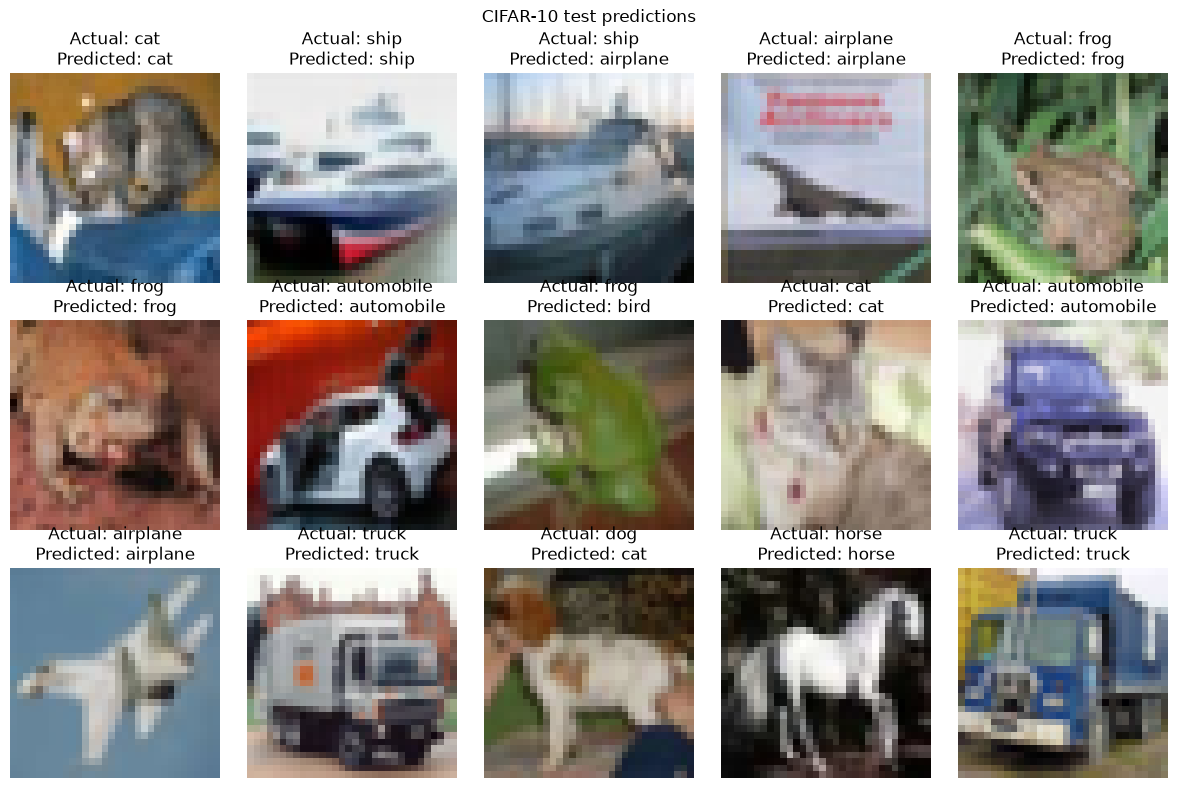

Conclusion: after 10 epochs, the CNN achieved 70.71% test accuracy.


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for metric, title, axis in (('accuracy', 'Accuracy', axes[0]), ('loss', 'Loss', axes[1])):
    axis.plot(history.history[metric], label='Training')
    axis.plot(history.history[f'val_{metric}'], label='Validation')
    axis.set_title(title)
    axis.set_xlabel('Epoch')
    axis.legend()
fig.tight_layout()
fig.savefig(FIGURES / 'exp10_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

test_loss, test_accuracy = model.evaluate(test_dataset, verbose=0)
print(f'Test loss: {test_loss:.4f} | Test accuracy: {test_accuracy:.4%}')
pd.DataFrame([{'epochs': len(history.history['loss']), 'test_loss': float(test_loss), 'test_accuracy': float(test_accuracy), 'train_samples': len(x_train), 'test_samples': len(x_test), 'device': 'GPU' if device_list else 'CPU'}]).to_csv(RESULTS / 'exp10_cifar10_metrics.csv', index=False)
sample_indices = np.arange(15)
sample_images = x_test[sample_indices].astype('float32') / 255.0
sample_predictions = model.predict(sample_images, verbose=0).argmax(axis=1)
fig, axes = plt.subplots(3, 5, figsize=(12, 8))
for index, ax in enumerate(axes.flat):
    ax.imshow(x_test[index])
    ax.set_title(f'Actual: {class_names[y_test[index]]}\nPredicted: {class_names[sample_predictions[index]]}')
    ax.axis('off')
fig.suptitle('CIFAR-10 test predictions')
fig.tight_layout()
fig.savefig(FIGURES / 'exp10_test_predictions.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Conclusion: after 10 epochs, the CNN achieved {test_accuracy:.2%} test accuracy.')